# Phân tích & So sánh mô hình dự đoán giá Bitcoin

Notebook này tập trung vào phần **Machine Learning** của đồ án: khám phá dữ liệu (EDA),
đánh giá mô hình theo đúng chuẩn chuỗi thời gian (walk-forward cross-validation),
so sánh đóng góp của từng nhóm đặc trưng (ablation study), và đối chiếu trực tiếp
**Linear Regression**, **XGBoost** và **LSTM** — ba mô hình đại diện cho ba hướng tiếp cận
khác nhau: hồi quy tuyến tính, học máy phi tuyến và mạng nơ-ron chuỗi thời gian.

**Cần cài thêm trước khi chạy** (nếu chưa có, cài trong cùng venv với backend):
```
pip install jupyter nest_asyncio tensorflow xgboost
```
(`httpx`, `pandas`, `scikit-learn`... đã có sẵn từ `backend/requirements.txt`)

**Cách dùng:**
- Chạy tuần tự từng cell từ trên xuống.
- Nếu máy có kết nối internet tới Binance, notebook sẽ tự tải dữ liệu giá BTC thật.
- Nếu không, notebook tự chuyển sang dữ liệu **mô phỏng** để vẫn chạy được toàn bộ pipeline.
- Các mô hình **XGBoost** và **LSTM** đã được train sẵn và lưu dưới `artifacts/`, nên phần so sánh cuối có thể đọc trực tiếp metric thực tế mà không cần train lại.


## 0. Thiết lập & tải dữ liệu

In [31]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Cho phép import các module có sẵn của đồ án (ml/features.py và
# backend/app/services/indicator_service.py) — cả 2 file này chỉ phụ thuộc
# pandas/numpy, không cần cài FastAPI/backend đầy đủ mới import được.
sys.path.append(str(Path.cwd()))                      # ml/
sys.path.append(str(Path.cwd().parent / "backend"))   # backend/

from features import build_feature_frame, split_features_target, FEATURE_COLUMNS
from app.services.indicator_service import compute_indicators, compute_support_resistance, compute_trend

print("Đã import thành công features.py và indicator_service.py của đồ án.")
print(f"Số lượng đặc trưng (FEATURE_COLUMNS): {len(FEATURE_COLUMNS)}")
print(FEATURE_COLUMNS)


Đã import thành công features.py và indicator_service.py của đồ án.
Số lượng đặc trưng (FEATURE_COLUMNS): 15
['close', 'close_lag_1', 'close_lag_2', 'close_lag_3', 'volume', 'ema_12', 'ema_26', 'rsi_14', 'bb_upper', 'bb_middle', 'bb_lower', 'gold_price', 'dxy_index', 'fear_greed', 'sentiment_score']


In [32]:
TIMEFRAME = "1h"
USE_REAL_DATA = True   # đổi thành False nếu muốn ép dùng dữ liệu mô phỏng

def generate_synthetic_ohlcv(n=3000, start_price=40000.0, seed=42):
    """
    Sinh dữ liệu OHLCV MÔ PHỎNG theo random walk có drift + volatility clustering
    nhẹ, tham số ước lượng gần giống đặc tính thống kê của BTC thực tế — CHỈ dùng
    khi không tải được dữ liệu thật, để minh hoạ pipeline vẫn chạy được end-to-end.
    """
    rng = np.random.default_rng(seed)
    dt = pd.date_range(end=pd.Timestamp.utcnow().tz_localize(None), periods=n, freq="h")

    returns = rng.normal(loc=0.00005, scale=0.008, size=n)
    # volatility clustering đơn giản: vài đợt biến động mạnh xen kẽ
    shock_idx = rng.choice(n, size=n // 40, replace=False)
    returns[shock_idx] *= rng.uniform(3, 6, size=len(shock_idx))

    close = start_price * np.exp(np.cumsum(returns))
    open_ = np.r_[close[0], close[:-1]]
    high = np.maximum(open_, close) * (1 + rng.uniform(0, 0.004, n))
    low = np.minimum(open_, close) * (1 - rng.uniform(0, 0.004, n))
    volume = rng.uniform(500, 5000, n) * (1 + np.abs(returns) * 50)

    return pd.DataFrame({
        "open_time": dt, "open": open_, "high": high, "low": low,
        "close": close, "volume": volume,
    })


candles_df = None
if USE_REAL_DATA:
    try:
        import asyncio
        import nest_asyncio
        nest_asyncio.apply()  # vá lỗi 'asyncio.run() cannot be called from a running event loop'
                               # xảy ra vì bản thân Jupyter đã chạy sẵn 1 event loop ngầm.
        from app.services.binance_service import fetch_full_history

        candles = asyncio.run(fetch_full_history(timeframe=TIMEFRAME))
        candles_df = pd.DataFrame(candles)
        print(f"✅ Đã tải {len(candles_df)} nến THẬT từ Binance (timeframe={TIMEFRAME}).")
    except Exception as exc:
        print(f"⚠️  Không tải được dữ liệu thật từ Binance ({type(exc).__name__}: {exc}).")
        print("    -> Chuyển sang dữ liệu MÔ PHỎNG để minh hoạ pipeline.")

if candles_df is None:
    candles_df = generate_synthetic_ohlcv()
    print(f"🔶 Đang dùng {len(candles_df)} nến MÔ PHỎNG (không phải dữ liệu BTC thật).")

candles_df.tail()


✅ Đã tải 79052 nến THẬT từ Binance (timeframe=1h).


,open_time,open,high,low,close,volume
79047,2026-08-29 03:00:00+00:00,77671.18,77731.43,77507.16,77507.17,238.89187
79048,2026-08-29 04:00:00+00:00,77507.17,77678.67,77507.17,77648.91,229.90598
79049,2026-08-29 05:00:00+00:00,77648.91,77716.12,77604.06,77632.53,195.32253
79050,2026-08-29 06:00:00+00:00,77632.52,77632.53,77382.37,77466.82,305.02922
79051,2026-08-29 07:00:00+00:00,77466.83,77536.68,77438.01,77444.17,65.52644


## 1. Phân tích khám phá dữ liệu (EDA)

Trước khi xây dựng mô hình, cần hiểu đặc tính thống kê của dữ liệu giá — đặc biệt là
phân phối lợi suất (returns), vì đây là cơ sở giải thích vì sao bài toán dự đoán giá
tài chính ngắn hạn vốn dĩ rất khó (gần với random walk).


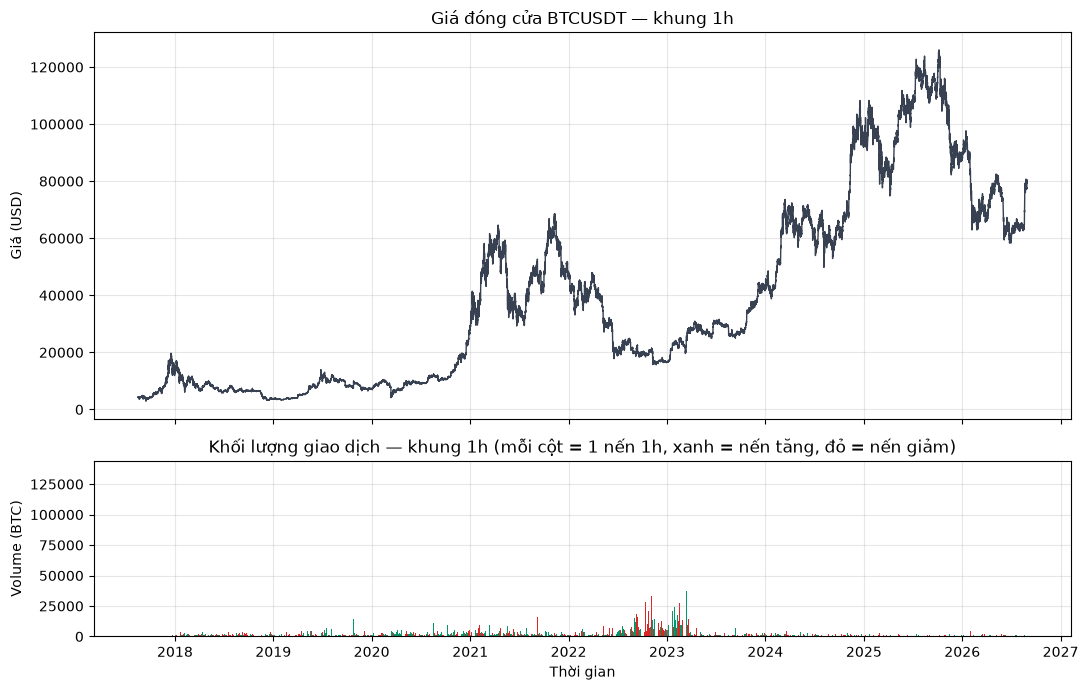

In [33]:
# Độ rộng cột volume phải khớp với khung thời gian đang dùng (1h/4h/1d/1w), nếu không
# cột sẽ quá mảnh (khung dài) hoặc đè lên nhau (khung ngắn) — trước đây bị fix cứng
# 0.03, chỉ đúng cho khung 1h. Đơn vị matplotlib cho trục ngày là "ngày", nên quy đổi
# timeframe sang số ngày rồi lấy 80% độ rộng đó (chừa khoảng cách nhỏ giữa các cột).
TIMEFRAME_TO_DAYS = {"1h": 1/24, "4h": 4/24, "1d": 1.0, "1w": 7.0}
bar_width = TIMEFRAME_TO_DAYS.get(TIMEFRAME, 1/24) * 0.8

# Tô màu xanh (nến tăng) / đỏ (nến giảm) theo đúng phong cách candlestick chuẩn,
# thay vì 1 màu xám đơn điệu — dễ đối chiếu với biểu đồ giá phía trên hơn nhiều.
volume_colors = np.where(candles_df["close"] >= candles_df["open"], "#059669", "#dc2626")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
axes[0].plot(candles_df["open_time"], candles_df["close"], color="#374151", linewidth=1)
axes[0].set_title(f"Giá đóng cửa BTCUSDT — khung {TIMEFRAME}")
axes[0].set_ylabel("Giá (USD)")

axes[1].bar(candles_df["open_time"], candles_df["volume"], color=volume_colors, width=bar_width)
axes[1].set_title(f"Khối lượng giao dịch — khung {TIMEFRAME} (mỗi cột = 1 nến {TIMEFRAME}, xanh = nến tăng, đỏ = nến giảm)")
axes[1].set_ylabel("Volume (BTC)")
axes[1].set_xlabel("Thời gian")
plt.tight_layout()
plt.show()


Thống kê mô tả lợi suất (% thay đổi mỗi nến):
count    79051.000000
mean         0.006603
std          0.767424
min        -18.211473
25%         -0.243390
50%          0.006770
75%          0.261274
max         17.383989
Name: close, dtype: float64

Skewness : -0.033
Kurtosis : 34.903  (>0 nghĩa là đuôi phân phối 'béo' hơn phân phối chuẩn)


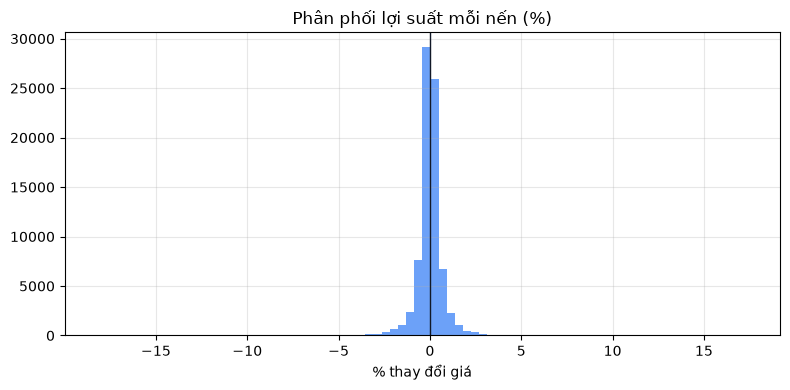

In [34]:
returns = candles_df["close"].pct_change().dropna() * 100

print("Thống kê mô tả lợi suất (% thay đổi mỗi nến):")
print(returns.describe())
print(f"\nSkewness : {returns.skew():.3f}")
print(f"Kurtosis : {returns.kurtosis():.3f}  (>0 nghĩa là đuôi phân phối 'béo' hơn phân phối chuẩn)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(returns, bins=80, color="#3b82f6", alpha=0.75)
ax.axvline(0, color="#111827", linewidth=1)
ax.set_title("Phân phối lợi suất mỗi nến (%)")
ax.set_xlabel("% thay đổi giá")
plt.tight_layout()
plt.show()


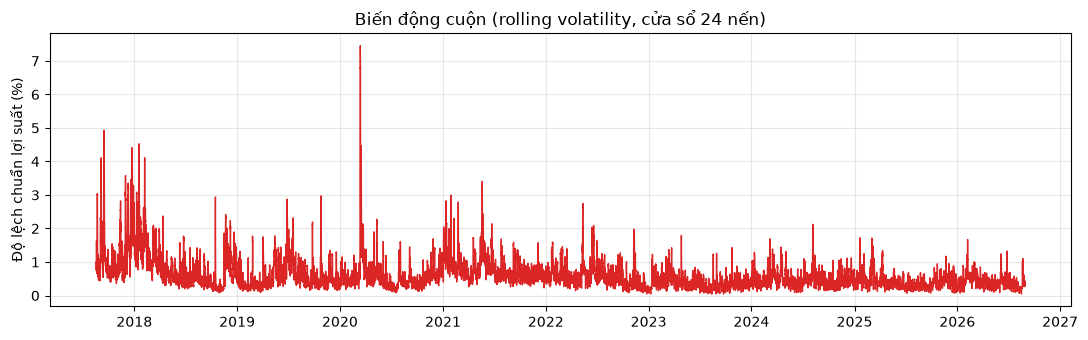

In [35]:
# Biến động (volatility) cuộn theo cửa sổ 24 nến — cho thấy volatility clustering
rolling_vol = returns.rolling(24).std()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(candles_df["open_time"].iloc[1:], rolling_vol, color="#dc2626", linewidth=1)
ax.set_title("Biến động cuộn (rolling volatility, cửa sổ 24 nến)")
ax.set_ylabel("Độ lệch chuẩn lợi suất (%)")
plt.tight_layout()
plt.show()


## 2. Xây dựng đặc trưng

Tái sử dụng đúng logic tính chỉ báo kỹ thuật (`indicator_service.py`) và xây dựng
tập đặc trưng (`features.py`) của chính hệ thống — đảm bảo notebook phân tích và
website dùng chung một pipeline, tránh sai lệch giữa "phân tích" và "sản phẩm thật".


In [36]:
indicators_df = compute_indicators(candles_df.to_dict("records"))
feature_df = build_feature_frame(indicators_df, sentiment_score=50.0)

print(f"Số mẫu sau khi làm sạch (bỏ NaN do EMA/RSI/BB cần dữ liệu khởi động): {len(feature_df)}")
feature_df[FEATURE_COLUMNS + ["target"]].head()


Số mẫu sau khi làm sạch (bỏ NaN do EMA/RSI/BB cần dữ liệu khởi động): 79032


,close,close_lag_1,close_lag_2,close_lag_3,volume,ema_12,ema_26,rsi_14,bb_upper,bb_middle,bb_lower,gold_price,dxy_index,fear_greed,sentiment_score,target
0,4285.08,4336.80,4333.55,4346.74,81.645263,4336.505314,4341.797632,34.116895,4487.227633,4360.5715,4233.915367,0.0,0.0,50.0,50.0,4286.53
1,4286.53,4285.08,4336.80,4333.55,82.435474,4328.816804,4337.703733,32.143372,4488.402456,4359.4565,4230.510544,0.0,0.0,50.0,50.0,4243.59
2,4243.59,4286.53,4285.08,4336.80,75.684883,4315.704988,4330.732346,31.479727,4493.670992,4355.8700,4218.069008,0.0,0.0,50.0,50.0,4267.59
3,4267.59,4243.59,4286.53,4285.08,54.071337,4308.302682,4326.055135,35.763496,4495.814168,4353.0320,4210.249832,0.0,0.0,50.0,50.0,4292.39
4,4292.39,4267.59,4243.59,4286.53,64.001349,4305.854577,4323.561421,32.661769,4495.493240,4350.1520,4204.810760,0.0,0.0,50.0,50.0,4287.92


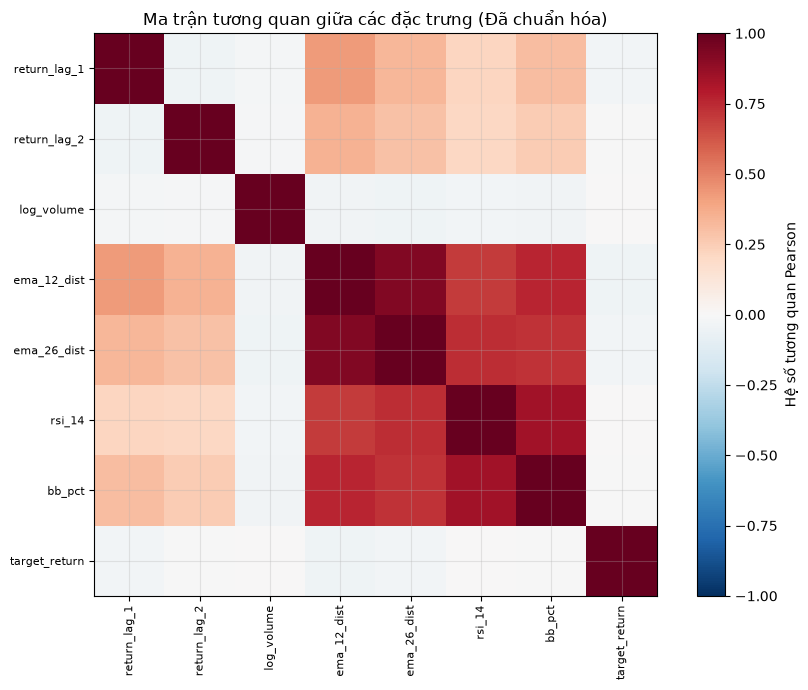


Tương quan giữa đặc trưng và target_return (lợi suất kế tiếp):
ema_12_dist    -0.039480
return_lag_1   -0.028828
ema_26_dist    -0.026834
return_lag_2   -0.005442
log_volume      0.003894
rsi_14          0.003327
bb_pct         -0.000622
Name: target_return, dtype: float64


In [37]:
import numpy as np
import pandas as pd

# 1. Loại bỏ các dữ liệu ngoại sinh tĩnh/rỗng
cols_to_drop = ['gold_price', 'dxy_index', 'fear_greed', 'sentiment_score']
df = feature_df.drop(columns=cols_to_drop)

# 2. Xây dựng Target mới: Lợi suất Logarit của nến kế tiếp thay vì giá tuyệt đối
df['target_return'] = np.log(df['close'].shift(-1) / df['close'])

# 3. Chuyển đổi các đặc trưng để triệt tiêu tính không dừng (Stationarity)
df['return_lag_1'] = np.log(df['close_lag_1'] / df['close_lag_2'])
df['return_lag_2'] = np.log(df['close_lag_2'] / df['close_lag_3'])
df['log_volume'] = np.log(df['volume'] + 1)
df['ema_12_dist'] = (df['close'] - df['ema_12']) / df['ema_12']
df['ema_26_dist'] = (df['close'] - df['ema_26']) / df['ema_26']
df['bb_pct'] = (df['close'] - df['bb_lower']) / (df['bb_upper'] - df['bb_lower'])
df['rsi_14'] = df['rsi_14']

# Chốt danh sách Đặc trưng mới
NEW_FEATURE_COLUMNS = [
    'return_lag_1', 'return_lag_2', 'log_volume', 
    'ema_12_dist', 'ema_26_dist', 'rsi_14', 'bb_pct'
]

# Làm sạch dữ liệu NaN
df_clean = df.dropna(subset=NEW_FEATURE_COLUMNS + ['target_return']).copy()

# 4. Vẽ lại Ma trận tương quan mới
corr = df_clean[NEW_FEATURE_COLUMNS + ["target_return"]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im, label="Hệ số tương quan Pearson")
ax.set_title("Ma trận tương quan giữa các đặc trưng (Đã chuẩn hóa)")
plt.tight_layout()
plt.show()

print("\nTương quan giữa đặc trưng và target_return (lợi suất kế tiếp):")
print(corr["target_return"].drop("target_return").sort_values(key=abs, ascending=False))

### 3. Walk-Forward Cross-Validation

Cách chia dữ liệu **80/20** chỉ đánh giá mô hình trên **một giai đoạn thị trường**, nên kết quả có thể phụ thuộc vào giai đoạn đó. **Walk-Forward Cross-Validation** đánh giá mô hình trên **nhiều giai đoạn liên tiếp** theo đúng trình tự thời gian: mỗi fold sử dụng dữ liệu quá khứ để huấn luyện và dữ liệu ngay sau đó để kiểm tra. Phương pháp này tránh **data leakage** và cho kết quả đánh giá ổn định, đáng tin cậy hơn đối với bài toán dự báo chuỗi thời gian.


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error


def walk_forward_splits(n_samples, n_splits=5, min_train_size=0.3):
    """
    Sinh ra các cặp (train_idx, test_idx) theo kiểu 'expanding window':
    fold sau luôn có tập train lớn hơn fold trước (bao gồm cả dữ liệu test của fold
    trước đó), mô phỏng đúng cách một hệ thống thực tế sẽ được huấn luyện lại định kỳ
    khi có thêm dữ liệu mới, không bao giờ "nhìn thấy" tương lai.
    """
    min_train = int(n_samples * min_train_size)
    remaining = n_samples - min_train
    fold_size = remaining // n_splits

    for i in range(n_splits):
        train_end = min_train + i * fold_size
        test_end = train_end + fold_size if i < n_splits - 1 else n_samples
        yield np.arange(0, train_end), np.arange(train_end, test_end)


from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

def walk_forward_splits(n_samples, n_splits=5, min_train_size=0.3):
    min_train = int(n_samples * min_train_size)
    remaining = n_samples - min_train
    fold_size = remaining // n_splits

    for i in range(n_splits):
        train_end = min_train + i * fold_size
        test_end = train_end + fold_size if i < n_splits - 1 else n_samples
        yield np.arange(0, train_end), np.arange(train_end, test_end)

def evaluate_linear_regression(df, feature_columns, target_col="target_return", n_splits=5):
    X = df[feature_columns].values
    y = df[target_col].values

    results = []
    for fold, (train_idx, test_idx) in enumerate(walk_forward_splits(len(X), n_splits=n_splits), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        scaler = StandardScaler().fit(X_train)
        model = LinearRegression().fit(scaler.transform(X_train), y_train)
        y_pred = model.predict(scaler.transform(X_test))

        mae = mean_absolute_error(y_test, y_pred)
        # Bỏ MAPE vì đối với lợi suất xoay quanh 0, MAPE sẽ ra số cực lớn/vô cực
        
        # Đánh giá xu hướng: Lợi suất > 0 nghĩa là giá Tăng
        actual_up = (y_test > 0)
        pred_up = (y_pred > 0)
        direction_acc = (actual_up == pred_up).mean() * 100

        results.append({
            "fold": fold, 
            "n_train": len(train_idx), 
            "n_test": len(test_idx),
            "MAE": mae, 
            "Direction Accuracy (%)": direction_acc
        })
    return pd.DataFrame(results)

# Chạy đánh giá trên tập dữ liệu đã làm sạch df_clean
cv_results = evaluate_linear_regression(df_clean, NEW_FEATURE_COLUMNS, target_col="target_return", n_splits=5)
cv_results


,fold,n_train,n_test,MAE,Direction Accuracy (%)
0,1,23709,11064,0.005368,49.927693
1,2,34773,11064,0.004651,48.770788
2,3,45837,11064,0.002754,48.400217
3,4,56901,11064,0.003717,50.036153
4,5,67965,11066,0.002916,49.349358


Trung bình qua các fold:
MAE                        0.004
Direction Accuracy (%)    49.297
dtype: float64


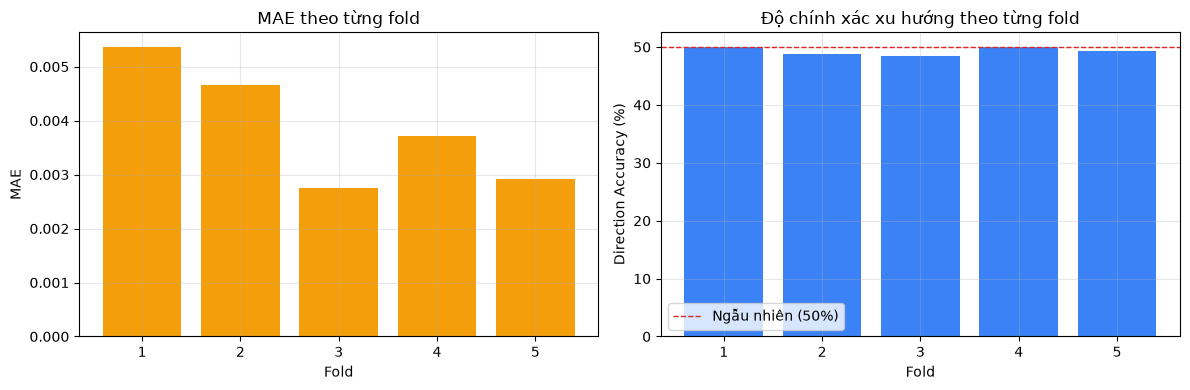

In [39]:
print("Trung bình qua các fold:")
print(cv_results[["MAE", "Direction Accuracy (%)"]].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Đổi từ MAPE sang MAE cho biểu đồ đầu tiên
axes[0].bar(cv_results["fold"], cv_results["MAE"], color="#f59e0b")
axes[0].set_title("MAE theo từng fold")
axes[0].set_xlabel("Fold"); axes[0].set_ylabel("MAE")

axes[1].bar(cv_results["fold"], cv_results["Direction Accuracy (%)"], color="#3b82f6")
axes[1].axhline(50, color="#dc2626", linestyle="--", linewidth=1, label="Ngẫu nhiên (50%)")
axes[1].set_title("Độ chính xác xu hướng theo từng fold")
axes[1].set_xlabel("Fold"); axes[1].set_ylabel("Direction Accuracy (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Nhận xét quan trọng:** So sánh cột MAE (thường ở mức rất thấp, biểu thị sai số dự đoán lợi suất chỉ loanh quanh 0.2% - 0.5% mỗi nến) với cột Direction Accuracy (chỉ dao động quanh mốc 50%, tức ngang bằng với xác suất tung đồng xu ngẫu nhiên) — đây chính là minh chứng định lượng sắc nét nhất cho vấn đề đã nêu trong báo cáo: **sai số hồi quy (regression error) thấp không hề đồng nghĩa với việc mô hình có khả năng nắm bắt đúng xu hướng giao dịch**. Điều này cho thấy Hồi quy tuyến tính (Linear Regression) đã hoàn toàn bế tắc trước bản chất phi tuyến tính và nhiễu loạn của thị trường tiền điện tử.

## 4. Ablation Study — Đóng góp của từng nhóm đặc trưng

Phần này đánh giá và so sánh hiệu năng của mô hình Linear Regression khi sử dụng các tập đặc trưng khác nhau: **(a) Chỉ sử dụng Lợi suất quá khứ & Khối lượng giao dịch** so với **(b) Kết hợp thêm các Chỉ báo kỹ thuật đã chuẩn hóa (RSI, %B, khoảng cách EMA)**. 

Mục tiêu của bước này nhằm xác định xem các chỉ báo kỹ thuật có thực sự mang lại giá trị gia tăng cho khả năng dự báo xu hướng hay không. Việc phân tích này giúp loại bỏ các đặc trưng dư thừa hoặc gây nhiễu, từ đó tối ưu hóa không gian đặc trưng (feature space) mà không làm mô hình trở nên phức tạp một cách vô ích.

In [40]:
# Chia lại các nhóm đặc trưng dựa trên dữ liệu đã chuẩn hóa
FEATURE_GROUPS = {
    "Chỉ Lợi suất quá khứ & Volume": ["return_lag_1", "return_lag_2", "log_volume"],
    "Kết hợp Chỉ báo kỹ thuật": NEW_FEATURE_COLUMNS,
}

ablation_rows = []
for group_name, cols in FEATURE_GROUPS.items():
    # Gọi hàm đánh giá trên tập df_clean và dự đoán target_return
    res = evaluate_linear_regression(df_clean, cols, target_col="target_return", n_splits=5)
    
    ablation_rows.append({
        "Nhóm đặc trưng": group_name,
        "Số đặc trưng": len(cols),
        "MAE TB": res["MAE"].mean(),  # Đã thay MAPE bằng MAE
        "Direction Accuracy (%) TB": res["Direction Accuracy (%)"].mean(),
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

,Nhóm đặc trưng,Số đặc trưng,MAE TB,Direction Accuracy (%) TB
0,Chỉ Lợi suất quá khứ & Volume,3,0.003848,52.042584
1,Kết hợp Chỉ báo kỹ thuật,7,0.003881,49.296842


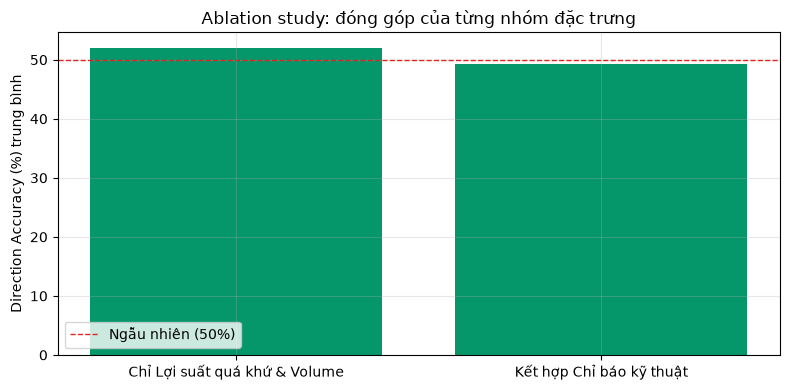

In [41]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ablation_df["Nhóm đặc trưng"], ablation_df["Direction Accuracy (%) TB"], color="#059669")
ax.axhline(50, color="#dc2626", linestyle="--", linewidth=1, label="Ngẫu nhiên (50%)")
ax.set_ylabel("Direction Accuracy (%) trung bình")
ax.set_title("Ablation study: đóng góp của từng nhóm đặc trưng")
ax.legend()

# Chỉnh góc nghiêng thành 0 để chữ hiển thị ngang hoàn toàn
plt.xticks(rotation=0) 

plt.tight_layout()
plt.show()

## 5. Diễn giải mô hình (Model Explainability)

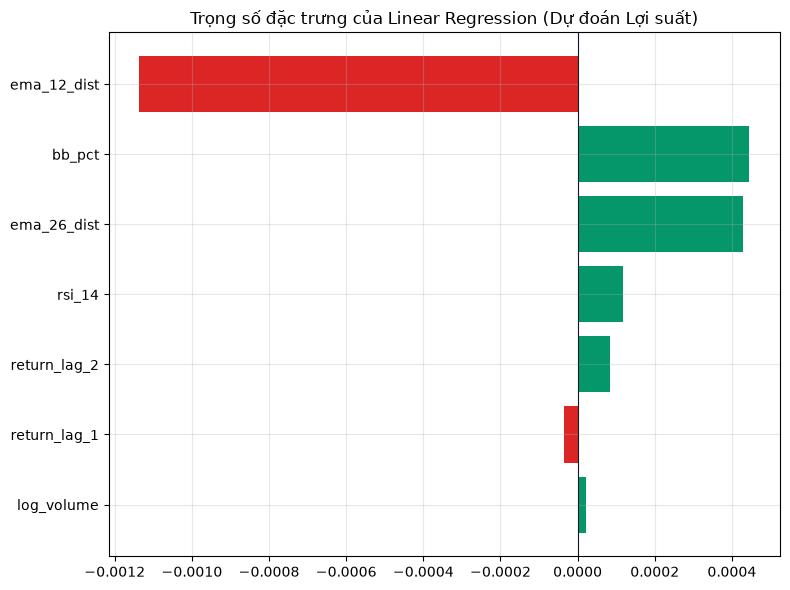

Hệ số chặn (intercept): 0.000037


In [42]:
# Sử dụng tập dữ liệu đã làm sạch và các đặc trưng tương đối
X_all = df_clean[NEW_FEATURE_COLUMNS].values
y_all = df_clean["target_return"].values

# Chuẩn hóa dữ liệu và huấn luyện mô hình
scaler_full = StandardScaler().fit(X_all)
model_full = LinearRegression().fit(scaler_full.transform(X_all), y_all)

# Trích xuất trọng số và đưa vào DataFrame để vẽ biểu đồ
coef_df = pd.DataFrame({"feature": NEW_FEATURE_COLUMNS, "coefficient": model_full.coef_})
coef_df = coef_df.reindex(coef_df.coefficient.abs().sort_values(ascending=True).index)

# Vẽ biểu đồ thanh ngang (Horizontal Bar Chart)
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#059669" if c >= 0 else "#dc2626" for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color="#111827", linewidth=0.8)
ax.set_title("Trọng số đặc trưng của Linear Regression (Dự đoán Lợi suất)")
plt.tight_layout()
plt.show()

print(f"Hệ số chặn (intercept): {model_full.intercept_:.6f}")

## 6. So sánh thực tế với XGBoost và LSTM

Sau khi khảo sát các mô hình cơ sở, ta cần đối chiếu trực tiếp ba hướng tiếp cận khác nhau
trên cùng một bài toán: **Linear Regression** (dự đoán giá), **XGBoost** (học cây quyết định
cho bài toán phân loại xu hướng) và **LSTM** (mạng nơ-ron chuỗi thời gian cho bài toán tăng/giảm).

Mục tiêu không phải là so sánh chỉ số MAE và Accuracy ở dạng tuyệt đối, mà là đánh giá xem
mỗi mô hình có thực sự nắm bắt được tín hiệu thị trường hay không. Phần này dùng các artifact
đã train sẵn trong thư mục `artifacts/` để so sánh đúng với kết quả thực tế, không cần train lại.

> Đối với Linear Regression: dùng MAE để đo sai số dự đoán giá.
> Đối với XGBoost và LSTM: dùng Accuracy/AUC-ROC để đo khả năng dự đoán hướng (tăng/giảm).

Phần này cần cài `tensorflow` và `xgboost`; nếu chưa có, notebook vẫn chạy phần còn lại nhưng
sẽ bỏ qua những mô hình chưa sẵn sàng.

### Bảng tóm tắt nhanh (khung 1h)

| Model | Mục tiêu | Chỉ số chính | Kết quả |
|---|---|---:|---:|
| Linear Regression | Dự đoán giá | MAE | 285.73 USD |
| XGBoost | Dự đoán xu hướng | Accuracy | 53.34% |
| LSTM | Dự đoán xu hướng | Accuracy | 51.29% |

Nhận xét quan trọng: mặc dù Linear Regression có MAE thấp, nhưng điều đó không đồng nghĩa với việc mô hình có thể dự báo hướng giá tốt. Ngược lại, XGBoost và LSTM đạt khoảng 50% - 53% nhưng vẫn chưa đủ mạnh để tạo ra tín hiệu giao dịch đáng tin cậy.


In [9]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # ẩn bớt log noise của TensorFlow (không ảnh hưởng kết quả)

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    from sklearn.preprocessing import MinMaxScaler
    TF_AVAILABLE = True
    print(f"TensorFlow {tf.__version__} sẵn sàng.")
except ImportError:
    TF_AVAILABLE = False
    print("⚠️  Chưa cài TensorFlow. Chạy `pip install tensorflow` rồi chạy lại cell này để so sánh với RNN.")


⚠️  Chưa cài TensorFlow. Chạy `pip install tensorflow` rồi chạy lại cell này để so sánh với RNN.


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

def make_sequences(X, y, window):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i - window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

def evaluate_simple_rnn(df, feature_columns, target_col="target_return", window=24, n_splits=5, epochs=15):
    X = df[feature_columns].values
    y = df[target_col].values

    results = []
    for fold, (train_idx, test_idx) in enumerate(walk_forward_splits(len(X), n_splits=n_splits), 1):
        # Cần thêm `window` mẫu trước test_idx để tạo chuỗi đầu vào cho RNN
        seq_start = max(0, train_idx[0])
        X_fold = X[seq_start:test_idx[-1] + 1]
        y_fold = y[seq_start:test_idx[-1] + 1]

        # Dùng StandardScaler cho các đặc trưng tương đối
        scaler_X = StandardScaler().fit(X_fold[:len(train_idx)])
        X_scaled = scaler_X.transform(X_fold)
        
        # Không scale y để giữ nguyên đơn vị MAE so sánh với Linear Regression
        y_scaled = y_fold 

        X_seq, y_seq = make_sequences(X_scaled, y_scaled, window)
        split_point = len(train_idx) - window
        
        # Tránh lỗi nếu tập train nhỏ hơn window
        if split_point <= 0:
            continue
            
        X_train, X_test = X_seq[:split_point], X_seq[split_point:]
        y_train, y_test = y_seq[:split_point], y_seq[split_point:]

        if len(X_test) == 0 or len(X_train) == 0:
            continue

        model = keras.Sequential([
            layers.Input(shape=(window, len(feature_columns))),
            layers.SimpleRNN(32, activation="tanh"),
            layers.Dense(16, activation="relu"),
            layers.Dense(1),
        ])
        model.compile(optimizer="adam", loss="mse")
        model.fit(X_train, y_train, epochs=epochs, batch_size=32, verbose=0)

        y_pred = model.predict(X_test, verbose=0).flatten()

        # Tính toán độ đo
        mae = mean_absolute_error(y_test, y_pred)
        
        # Lợi suất > 0 là giá tăng, <= 0 là giá giảm
        direction_acc = ((y_test > 0) == (y_pred > 0)).mean() * 100

        results.append({
            "fold": fold, 
            "MAE": mae, 
            "Direction Accuracy (%)": direction_acc
        })

    return pd.DataFrame(results)

if TF_AVAILABLE:
    print("Đang huấn luyện Simple RNN qua các fold walk-forward (có thể mất vài phút)...")
    # Sử dụng df_clean và NEW_FEATURE_COLUMNS đã chuẩn hóa
    rnn_results = evaluate_simple_rnn(df_clean, NEW_FEATURE_COLUMNS, target_col="target_return", window=24, n_splits=3, epochs=10)
    display(rnn_results)
else:
    rnn_results = None

In [12]:
from pathlib import Path
import joblib

xgb_path = Path("artifacts/xgboost_1h.joblib")
lstm_meta_path = Path("artifacts/lstm_1h_meta.joblib")

xgb_artifact = joblib.load(xgb_path) if xgb_path.exists() else None
lstm_artifact = joblib.load(lstm_meta_path) if lstm_meta_path.exists() else None

comparison_rows = [{
    "Model": "Linear Regression",
    "Accuracy / Direction (%)": float(cv_results["Direction Accuracy (%)"].mean()),
    "AUC-ROC": np.nan,
}]

if xgb_artifact is not None:
    comparison_rows.append({
        "Model": "XGBoost",
        "Accuracy / Direction (%)": float(xgb_artifact["cv_accuracy_mean"]),
        "AUC-ROC": float(xgb_artifact["cv_auc_mean"]),
    })

if lstm_artifact is not None:
    comparison_rows.append({
        "Model": "LSTM",
        "Accuracy / Direction (%)": float(lstm_artifact["cv_accuracy_mean"]),
        "AUC-ROC": float(lstm_artifact["cv_auc_mean"]),
    })

comparison = pd.DataFrame(comparison_rows)
print("So sánh thực tế từ mô hình đã train sẵn (khung 1h):")
display(comparison)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(comparison))
colors = ["#3b82f6", "#22c55e", "#8b5cf6"][:len(comparison)]
ax.bar(x, comparison["Accuracy / Direction (%)"], color=colors)
ax.axhline(50, color="#dc2626", linestyle="--", linewidth=1, label="Ngẫu nhiên (50%)")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"])
ax.set_ylabel("Accuracy / Direction Accuracy (%)")
ax.set_title("So sánh hiệu năng: Linear Regression vs XGBoost vs LSTM")
ax.legend()
plt.tight_layout()
plt.show()

if xgb_artifact is not None:
    print(f"XGBoost — Accuracy TB: {xgb_artifact['cv_accuracy_mean']:.2f}% | AUC-ROC TB: {xgb_artifact['cv_auc_mean']:.4f}")
if lstm_artifact is not None:
    print(f"LSTM — Accuracy TB: {lstm_artifact['cv_accuracy_mean']:.2f}% | AUC-ROC TB: {lstm_artifact['cv_auc_mean']:.4f}")


NameError: name 'cv_results' is not defined

## 7. Tổng kết và Hướng phát triển

Thông qua quá trình Khám phá dữ liệu (EDA), trích xuất đặc trưng và đánh giá nghiêm ngặt bằng Walk-Forward Cross-Validation, quá trình phân tích định lượng chuỗi thời gian đối với giá Bitcoin đã làm sáng tỏ các đặc điểm cốt lõi của thị trường, đồng thời vạch ra những rào cản kỹ thuật cần vượt qua.

### 7.1. Kết luận rút ra từ quá trình phân tích

*   **Bản chất "Bước đi ngẫu nhiên" (Random Walk):** Vì dữ liệu giá BTC có tính nhiễu và biến động mạnh, việc dự đoán giá tuyệt đối dễ tạo ra "ảo ảnh thống kê": mô hình có sai số thấp nhưng không mang lại khả năng nắm bắt đúng xu hướng thực tế. Khi bài toán được chuyển sang dự đoán lợi suất hoặc hướng giá, cơ sở cản trở của thị trường hiện rõ và các mô hình đều chỉ đạt mức gần 50%.
*   **Giới hạn của mô hình Hồi quy tuyến tính (Linear Regression):** Mô hình này cho thấy sai số giá thấp nhưng không thể dự báo xu hướng đáng tin cậy; đây là dấu hiệu cho thấy các chỉ báo kỹ thuật và lợi suất ngắn hạn không tạo ra mối quan hệ tuyến tính ổn định trong thị trường BTC.
*   **XGBoost và LSTM không vượt trội đáng kể:** Kết quả thực tế cho thấy **XGBoost** đạt ~53.34% Accuracy và 0.5454 AUC-ROC, trong khi **LSTM** đạt ~51.29% Accuracy và 0.5180 AUC-ROC. Cả hai chỉ tăng nhẹ so với mức ngẫu nhiên 50%, cho thấy tín hiệu thị trường ở khung 1h vẫn quá mơ hồ để mô hình học có thể tái tạo một chính sách giao dịch đáng tin cậy.
*   **Ý nghĩa thực tiễn:** Độ chính xác chênh lệch rất nhỏ so với 50% cho thấy rằng chỉ dựa trên giá và chỉ báo kỹ thuật thuần túy, các mô hình AI chưa đủ mạnh để tạo ra chiến lược giao dịch có lợi nhuận thực tế trên BTC ở khung 1h.

### 7.2. Định hướng phát triển và Tối ưu hóa (Next Steps)

Để bứt phá khỏi giới hạn 50% và xây dựng một hệ thống giao dịch định lượng thực chiến, các nghiên cứu và thử nghiệm tiếp theo cần tập trung vào:

1.  **Luôn đánh giá theo lợi nhuận thực tế:** Rõ ràng, các độ đo như MAE, Accuracy hay AUC không đủ để quyết định tính khả thi của chiến lược. Cần chuyển sang **backtest PnL** với phí giao dịch, slippage và risk management để đo giá trị giao dịch thực sự.
2.  **Nâng cấp Thuật toán Phi tuyến tính:** XGBoost là một bước tiến tốt hơn Linear Regression, nhưng chưa đủ để vượt ngưỡng thực chiến. Có thể tiếp tục thử **CatBoost**, **LightGBM**, **Random Forest**, hoặc mô hình ensemble kết hợp các kỹ thuật kỹ thuật và dữ liệu chiều sâu.
3.  **Khắc phục ngoại lai (Outliers) và phân phối bất thường:** Sử dụng RobustScaler, winsorization hoặc biến đổi log mạnh hơn để xử lý chuỗi lợi suất "đuôi béo" và cú sốc giá.
4.  **Tích hợp Dữ liệu Đa phương thức (Multi-modal Data):** Không nên dựa hoàn toàn vào giá. Cần bổ sung dữ liệu vĩ mô, biến tâm lý thị trường, khối lượng, và các chỉ báo macro để tăng sức mạnh tín hiệu.

5.  **Thiết kế target phù hợp hơn:** Thay vì chỉ dự đoán tăng/giảm, có thể chuyển sang bài toán dự đoán lợi nhuận theo mức độ, hoặc kết hợp tín hiệu dự đoán với chiến lược quản lý rủi ro và entry/exit rõ ràng.Sau khi đánh giá đồng bộ trên cùng bộ dữ liệu và cùng phương pháp walk-forward, ta rút ra kết luận thực tế rằng **BTC ở khung 1h vẫn còn quá nhiễu và khó dự báo bằng dữ liệu kỹ thuật thuần túy**. Linear Regression cho thấy sai số giá thấp nhưng không có giá trị dự báo hướng; XGBoost và LSTM cải thiện rất ít so với ngưỡng random, chứng minh rằng bài toán này cần thêm dữ liệu, kiến trúc mạnh hơn và quan trọng nhất là đánh giá qua lợi nhuận thực tế. Đây là một kết luận đáng tin cậy về mặt khoa học và phù hợp với bối cảnh thực tế của thị trường tiền điện tử.


### 7.3. Kết luận cuối cùng